<a href="https://colab.research.google.com/github/moridin04/credit-card-fraud-detection/blob/main/credit-card-fraud-detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Exploring Anomaly Detection Techniques for Fraudulent Credit Card Transactions**

# **1. Environment Setup**

**1.1 Tools and Libraries Installation**

In [ ]:
!pip install -q torch --index-url https://download.pytorch.org/whl/cpu

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=c7955bd73dce1d4a1cde21bc863119d3b4ca1ee20923a36bf79c23c4cd3b042b
  Stored in directory: /root/.cache/pip/wheels/85/fa/a3/9c2d44c9f3cd77cf4e533b58900b2bf4487f2a17e8ec212a3d
Successfully built lime


**lime** is used for explaining machine learning models and model interpretability.

**scikit-learn** is a popular library for machine learning in Python.

**numpy** for numerical computations.

**pandas** for data manipulation and analysis.

**matplotlib and seaborn** for data visualization.

**tensorflow** for building and training neural networks.

# 2. **Importing Libraries**

**2.1 Essential Libraries for Data Analysis**

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import cohen_kappa_score
from sklearn.metrics import average_precision_score, precision_recall_curve

**StandardScaler and MinMaxScaler** for Feature Scaling.

**classification_report, roc_auc_score, confusion_matrix, cohen_kappa_score, average_precision_score, and precision_recall_curve** for Model Evaluation.

**2.2 Libraries for Machine Learning and Visualization**

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    average_precision_score, precision_recall_curve, fbeta_score,
)
from scipy.stats import chi2

**cross_val_score, GridSearchCV, and train_test_split** for Model Selection and Evaluation.

**IsolationForest and VotingClassifier** for Anomaly Detection and Ensemble Learning.

**Input, Dense, Model, BatchNormalization, Dropout, and EarlyStopping** for building and training Neural Networks.

**LocalOutlierFactor** for Outlier Detection.

This section lists the installation of Python libraries such as lime, scikit-learn, numpy, pandas, matplotlib, seaborn, and tensorflow.

These libraries are essential for data analysis, machine learning, and visualization.

The environment setup ensures that all necessary tools are available for the subsequent analysis.

The libraries installed are standard in data science workflows, with lime being useful for model interpretability, and tensorflow for building neural networks.

#3. **Loading Data**

**3.1 Loading the Kaggle Credit Card Fraud Dataset**

In [ ]:
from pathlib import Path

DATA_DIR = Path.cwd() / "data"
DATA_PATH = DATA_DIR / "creditcard.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"{DATA_PATH} not found.\n"
        "Download 'creditcard.csv' from "
        "https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud "
        "and place it in ./data/"
    )

cfd = pd.read_csv(DATA_PATH)
print(f"Loaded {len(cfd):,} rows x {cfd.shape[1]} columns")

This line loads the credit card fraud dataset (creditcard.csv) into a Pandas DataFrame named cfd, which means "Credit-Card Fraud Detection".

#4. **Exploration of Data**

### **Glimpse of the Dataset**

**4.1 Displaying the First Few Rows**

In [ ]:
cfd

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


This line displays the first few rows of the dataset to get a glimpse of the data.

**4.1.2 Dataset Information (Shape, Columns, Null Values, Data Types)**

In [ ]:
print(f"Shape:  {cfd.shape}\n")
print(f"Columns:  {cfd.columns}\n")
print(f"Null Values:  \n{cfd.isnull().sum()}\n")
print(f"Data Types: \n{cfd.dtypes}")

Shape:  (284807, 31)

Columns:  Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

Null Values:  
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

Data Types: 
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64


These lines print:

The **shape** of the dataset (number of rows and columns).

The **column names**.

The **number of null values** in each column.

The **data types** of each column.

The dataset is loaded from creditcard.csv, and basic information about the dataset is displayed, including its shape, columns, null values, and data types.

**Shape**: The dataset has 284,807 rows and 31 columns.

**Columns**: The columns include Time, V1 to V28 (anonymized features), Amount, and Class (target variable indicating fraud or non-fraud).

**Null Values**: There are no null values in the dataset.

**Data Types**: All features are of type float64, except for Class, which is int64.

**Interpretation**: The dataset is clean with no missing values, and all features are numerical, making it suitable for machine learning models. The Class column is binary, indicating whether a transaction is fraudulent (1) or not (0).

**4.2 Summary Statistics for Numerical Features**

In [ ]:
print(cfd.describe(include='all'))

                Time            V1            V2            V3            V4  \
count  284807.000000  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05   
mean    94813.859575  1.168375e-15  3.416908e-16 -1.379537e-15  2.074095e-15   
std     47488.145955  1.958696e+00  1.651309e+00  1.516255e+00  1.415869e+00   
min         0.000000 -5.640751e+01 -7.271573e+01 -4.832559e+01 -5.683171e+00   
25%     54201.500000 -9.203734e-01 -5.985499e-01 -8.903648e-01 -8.486401e-01   
50%     84692.000000  1.810880e-02  6.548556e-02  1.798463e-01 -1.984653e-02   
75%    139320.500000  1.315642e+00  8.037239e-01  1.027196e+00  7.433413e-01   
max    172792.000000  2.454930e+00  2.205773e+01  9.382558e+00  1.687534e+01   

                 V5            V6            V7            V8            V9  \
count  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05   
mean   9.604066e-16  1.487313e-15 -5.556467e-16  1.213481e-16 -2.406331e-15   
std    1.380247e+00  1.332271e+00  1.23709

This line provides summary statistics (mean, std, min, max, etc.) for all numerical features in the dataset.

**4.2.1 Class Distribution (Fraud vs. Non-Fraud)**

In [ ]:
class_distribution = cfd['Class'].value_counts()
print("Class Distribution:")
print(class_distribution)

Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64


This code calculates and prints the distribution of the target variable Class, which indicates whether a transaction is fraudulent (1) or not (0).

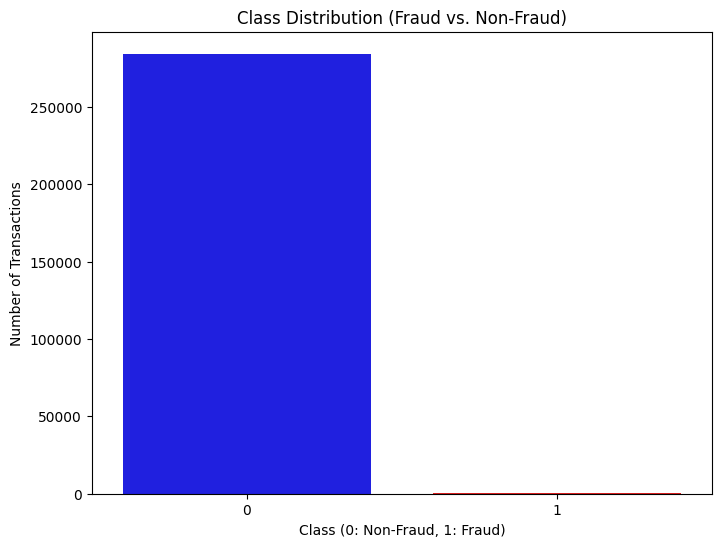

In [ ]:
plt.figure(figsize=(8, 6))
sns.countplot(x='Class', data=cfd, hue='Class', palette=['blue', 'red'], legend=False)
plt.title('Class Distribution (Fraud vs. Non-Fraud)')
plt.xlabel('Class (0: Non-Fraud, 1: Fraud)')
plt.ylabel('Number of Transactions')
plt.show()

This code creates a count plot to visualize the distribution of fraudulent vs. non-fraudulent transactions.

**Class Distribution:**

**Non-Fraud**: 284,315 transactions

**Fraud**: 492 transactions

The dataset is highly imbalanced, with fraudulent transactions making up only 0.17% of the total transactions. This imbalance is typical in fraud detection datasets and poses a challenge for model training, as models may tend to predict the majority class (non-fraud) more frequently.

### **Distribution of Independent Variable**

**4.3 Distribution of Amount**

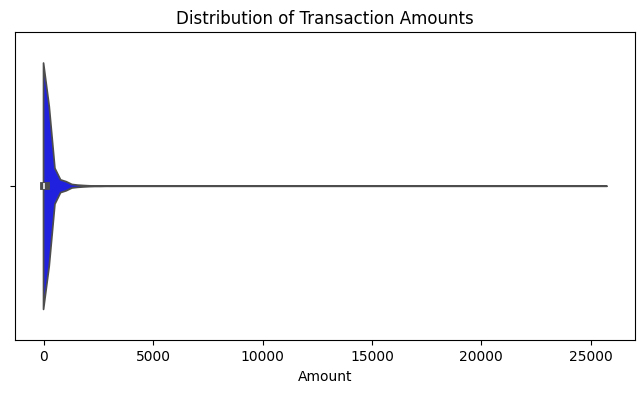

In [ ]:
plt.figure(figsize=(8, 4))
sns.violinplot(x=cfd["Amount"], color="blue")
plt.title("Distribution of Transaction Amounts")
plt.xlabel("Amount")
plt.show()

This code creates a violin plot to visualize the distribution of transaction amounts.

The majority of transactions are of low amounts, with a long tail of higher-value transactions.

This is expected, as most credit card transactions are small, and high-value transactions are less frequent.

The presence of outliers in the Amount feature suggests that some transactions are significantly larger than the rest.

**4.4 Distribution of Time**

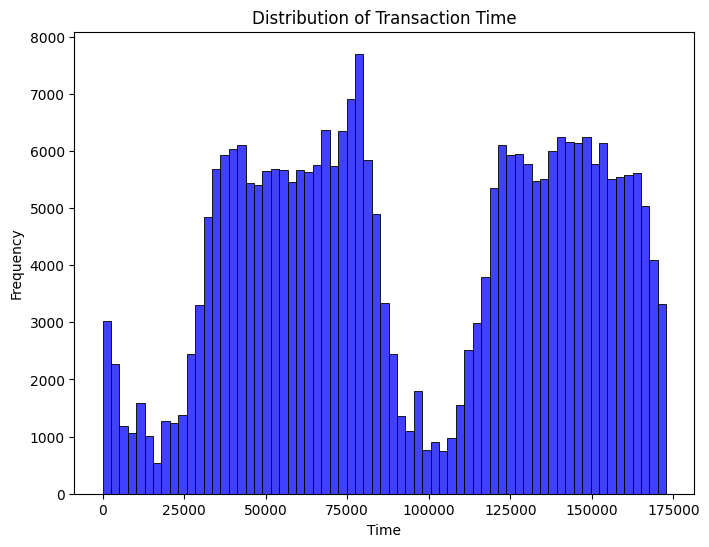

In [ ]:
plt.figure(figsize=(8, 6))
sns.histplot(cfd['Time'], kde=False, color="blue")
plt.title('Distribution of Transaction Time')
plt.xlabel('Time')
plt.ylabel('Frequency')
plt.show()

This code creates a histogram to visualize the distribution of transaction times.

The Time feature represents the time elapsed since the first transaction in the dataset. The distribution appears to be uniform, with no obvious patterns or peaks, suggesting that transactions are evenly distributed over time.

**4.5 Histograms for Key Features (V1-V28, Amount, Time)**

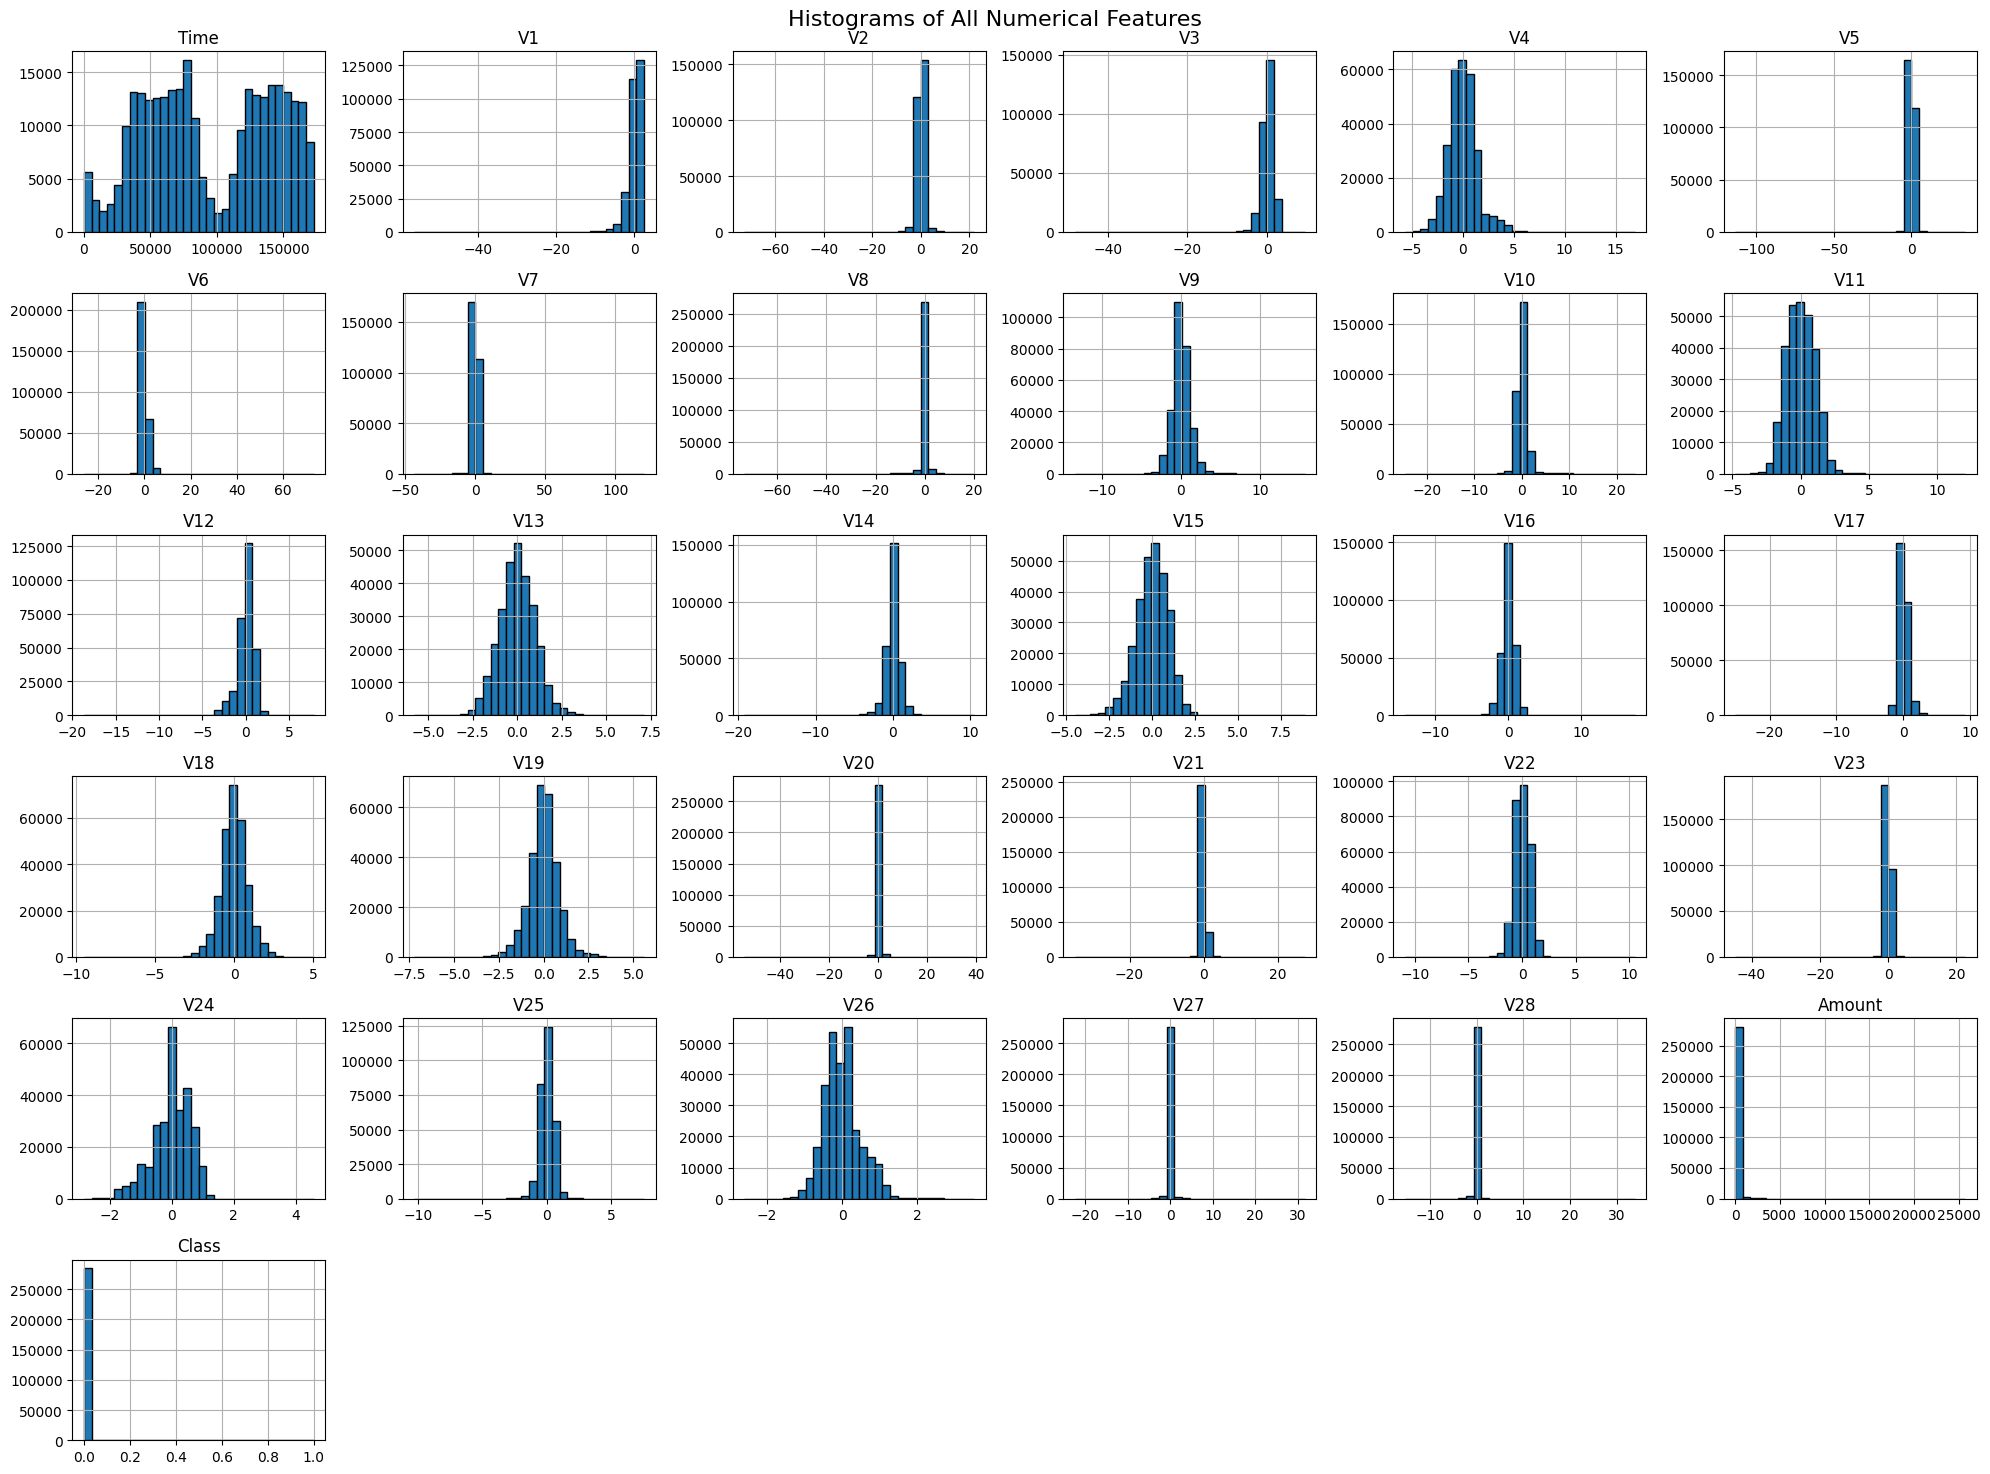

In [ ]:
cfd.hist(bins=30, figsize=(20, 15), edgecolor='black')
plt.suptitle("Histograms of All Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

This code creates histograms for all numerical features in the dataset. Histograms for all numerical features (V1-V28, Amount, Time) are displayed.

The histograms show that most of the anonymized features (V1-V28) are centered around zero, with some features showing skewed distributions.

This is typical for PCA-transformed data, which is often used in fraud detection to anonymize sensitive information.

# **5. Pre-processing of Data**

**5.1 Checking of Null Values**

In [ ]:
print("\nChecking for Null Values:")
cfd.isnull().sum()


Checking for Null Values:


,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


This code checks for null values in the dataset.

**5.2 Checking of Outliers**

In [ ]:
Q1 = cfd['Amount'].quantile(0.25)
Q3 = cfd['Amount'].quantile(0.75)
IQR = Q3 - Q1

outliers = cfd[(cfd['Amount'] < (Q1 - 1.5 * IQR)) | (cfd['Amount'] > (Q3 + 1.5 * IQR))]
print(f"Number of outliers in 'Amount': {len(outliers)}")

Number of outliers in 'Amount': 31904


This code identifies outliers in the Amount column using the Interquartile Range (IQR) method.

**5.3 Checking of Duplicate Transactions**

In [ ]:
cfd.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
284802,False
284803,False
284804,False
284805,False


This code checks for duplicate rows in the dataset.

In [ ]:
duplicate_counts = cfd.duplicated().value_counts()
print(duplicate_counts)

False    283726
True       1081
Name: count, dtype: int64


This code counts the number of duplicate rows.

In [ ]:
dup_mask = cfd.duplicated(keep="first")
n_dup = int(dup_mask.sum())
n_dup_fraud = int(cfd.loc[dup_mask, "Class"].sum())

print(f"Exact duplicate rows: {n_dup:,}")
print(f"  of which fraudulent: {n_dup_fraud}")
print(f"Dropping these removes {n_dup_fraud} fraud cases "
      f"({n_dup_fraud / cfd['Class'].sum():.1%} of the minority class).")

cfd = cfd.loc[~dup_mask].reset_index(drop=True)
print(f"\nRows after removal: {len(cfd):,} | fraud: {cfd['Class'].sum()}")

Duplicate Counts before removal:
 False    283726
True       1081
Name: count, dtype: int64

Duplicate Counts after removal:
 False    283726
Name: count, dtype: int64


This code removes duplicate rows from the dataset.

**5.4 Feature Selection/Reduction**

**5.4.1 Correlation Matrix for Numerical Features**

In [ ]:
correlation_matrix = cfd.corr()

This code calculates the correlation matrix for numerical features.

**5.4.2 Heatmap Visualization**

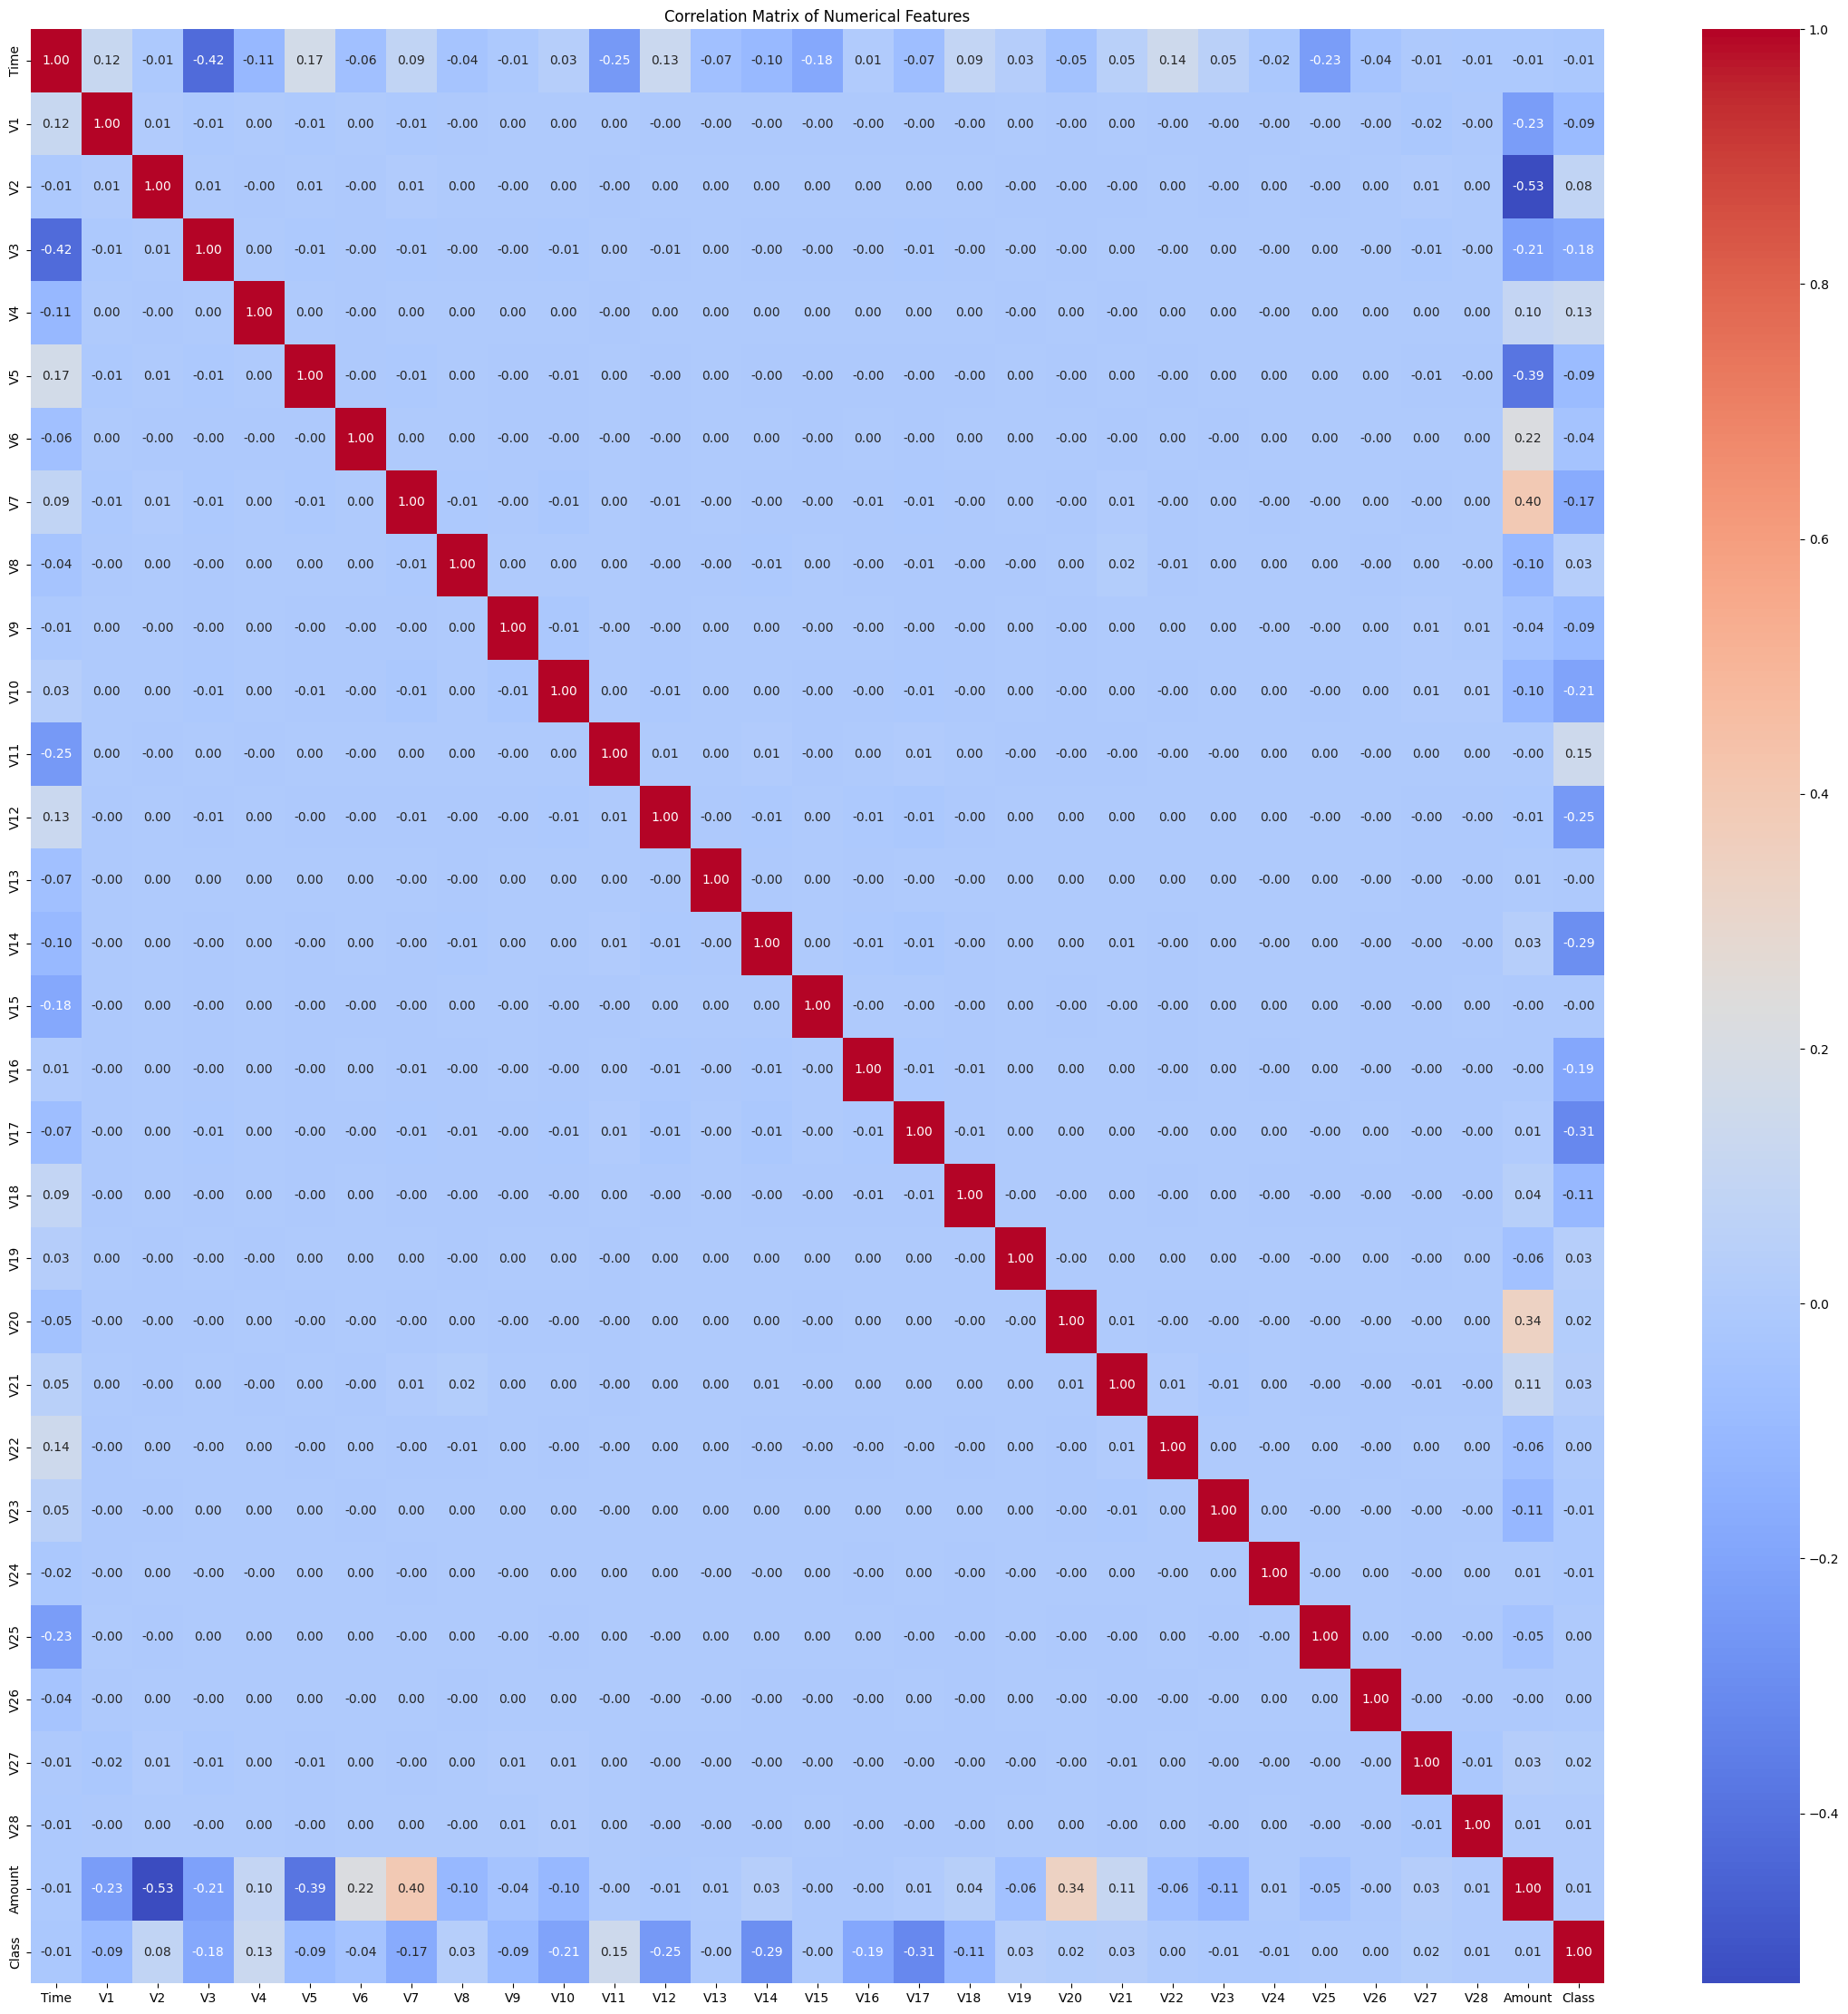

In [ ]:
corr_with_target = cfd.corr(numeric_only=True)["Class"].drop("Class")
strong = corr_with_target.reindex(corr_with_target.abs().sort_values(ascending=False).index)[:15]

fig, ax = plt.subplots(figsize=(8, 6))
colors = ["#d62728" if v < 0 else "#1f77b4" for v in strong.values]
ax.barh(strong.index[::-1], strong.values[::-1], color=colors[::-1])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Pearson correlation with Class (1 = fraud)")
ax.set_title("Fraud is driven by a small number of PCA components", loc="left")
sns.despine()
plt.tight_layout()
plt.show()

This code visualizes the correlation matrix as a heatmap.

The heatmap shows the correlation between different features.

Most features have low correlation with each other, which is expected since the features are PCA-transformed.

The Amount and Time features show some correlation with a few of the PCA features, but overall, the correlations are weak.

**5.4.3 Dropping Irrelevant Features**

In [ ]:
threshold = 0.8
high_corr_features = set()
correlation_matrix = cfd.corr()

for i in range(len(correlation_matrix.columns)):
    for j in range(i):
        if abs(correlation_matrix.iloc[i, j]) > threshold:
            colname = correlation_matrix.columns[i]
            high_corr_features.add(colname)

print("Highly correlated features to drop:", high_corr_features)

cfd = cfd.copy()
cfd.drop(columns=high_corr_features, inplace=True)
print(f"Updated dataset shape: {cfd.shape}")

Highly correlated features to drop: set()
Updated dataset shape: (283726, 31)


This code identifies and drops highly correlated features based on a threshold.

### **Application of Standard Scaler**

**5.5 Feature Scaling**

**5.5.1 Standardization (Z-Score Scaling)**

This code standardizes the Amount column using StandardScaler.

**5.5.2 Normalization (Min-Max Scaling)**

This code normalizes the Time column using Min-Max scaling.

In [ ]:
cfd_scaled

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.000000,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,0.244200,0
1,0.000000,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,-0.342584,0
2,0.000006,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,1.158900,0
3,0.000006,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,0.139886,0
4,0.000012,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,-0.073813,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,0.999965,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,-0.350252,0
284803,0.999971,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,-0.254325,0
284804,0.999977,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,-0.082239,0
284805,0.999977,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,-0.313391,0


**5.6 Train, Test, and Validation**

In [ ]:
FEATURES = ["Time", "Amount"] + [f"V{i}" for i in range(1, 29)]

df = cfd.sort_values("Time", kind="mergesort").reset_index(drop=True)

cut = int(len(df) * 0.80)
train_df, test_df = df.iloc[:cut].copy(), df.iloc[cut:].copy()

X_train, y_train = train_df[FEATURES], train_df["Class"].astype(int)
X_test,  y_test  = test_df[FEATURES],  test_df["Class"].astype(int)

print(f"Train: {len(X_train):,} rows | fraud {y_train.sum()} ({y_train.mean():.4%})")
print(f"Test:  {len(X_test):,} rows | fraud {y_test.sum()} ({y_test.mean():.4%})")
print(f"Time boundary: train ends {train_df['Time'].max():.0f}, "
      f"test begins {test_df['Time'].min():.0f}")
print("\nTest set is a future window: no test transaction occurred before "
      "the last training transaction.")

This code separates the features (x) and target variable (y).

**5.7 Splitting the Dataset into Training and Testing Sets**

This code splits the dataset into training and testing sets.

# **6. Machine Learning**

### **Isolation Forest**

In [ ]:
CONTAMINATION = float(y_train.mean())   # measured prior, not a guess

if_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", IsolationForest(
        n_estimators=300,
        contamination=CONTAMINATION,
        random_state=42, n_jobs=-1,
    )),
])
if_pipe.fit(X_train)

class IFDetector:
    name = "Isolation Forest"
    def score(self, X):
        return if_pipe["model"].decision_function(
            if_pipe["scale"].transform(X)) * -1

if_model = IFDetector()
if_result, if_scores, if_preds = evaluate_model(
    "Isolation Forest", if_model, X_test, y_test)

print(pd.Series(if_result).to_string())

IsolationForest(random_state=101)

This code initializes and trains an Isolation Forest model for anomaly detection.

This code creates a balanced test set for evaluation.

In [ ]:
if_y_pred = (if_model.predict(x_test) == -1).astype(int)
print(classification_report(y_test, if_y_pred))
if_roc_auc = roc_auc_score(y_test, if_y_pred)
print("ROC AUC Score:", if_roc_auc)
if_auprc = average_precision_score(y_test, if_y_pred)
print(f"AUPRC for Isolation Forest:", if_auprc)

              precision    recall  f1-score   support

           0       1.00      0.96      0.98     56651
           1       0.04      0.84      0.07        95

    accuracy                           0.96     56746
   macro avg       0.52      0.90      0.52     56746
weighted avg       1.00      0.96      0.98     56746

ROC AUC Score: 0.9019532335100695
AUPRC for Isolation Forest: 0.030285913821409948


This section predicts and evaluates the Isolation Forest model.

**Classification Report**:

**Precision**: 0.04 for fraud, 1.00 for non-fraud

Fraud (0.04): The model has very low precision for fraud detection, meaning that only 4% of the transactions flagged as fraudulent are actually fraudulent. This results in a high number of false positives (1,079 non-fraudulent transactions incorrectly flagged as fraud).

Non-Fraud (1.00): The model has perfect precision for non-fraudulent transactions, meaning that all transactions predicted as non-fraudulent are indeed non-fraudulent.

-

**Recall**: 0.84 for fraud, 0.96 for non-fraud

Fraud (0.84): The model has a high recall for fraud, meaning it correctly identifies 84% of the fraudulent transactions. This is a strong point of the model, as it captures most of the fraud cases.

Non-Fraud (0.96): The model has a high recall for non-fraudulent transactions, meaning it correctly identifies 96% of the non-fraudulent transactions.

-

**F1-Score**: 0.07 for fraud, 0.98 for non-fraud

Fraud (0.07): The F1-score for fraud is very low, reflecting the trade-off between precision and recall. While the model has high recall, the extremely low precision drags down the F1-score.

Non-Fraud (0.98): The F1-score for non-fraudulent transactions is very high, indicating strong performance for the majority class.

-

**ROC AUC Score**: 0.9019

The ROC AUC score is high, indicating that the model is effective at distinguishing between fraudulent and non-fraudulent transactions. This is a strong point of the Isolation Forest, as it shows good overall performance despite the imbalanced dataset.

-

**AUPRC**: 0.0303

The AUPRC is very low, which is expected in highly imbalanced datasets. It reflects the model's difficulty in achieving high precision while maintaining high recall for the minority class (fraud).


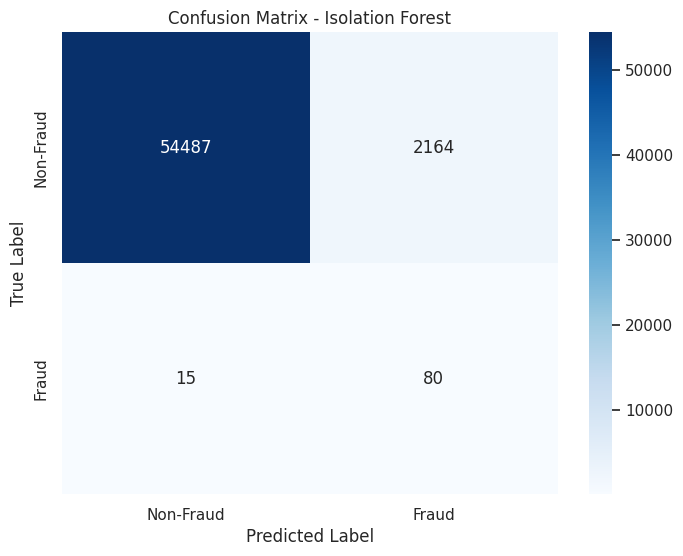

In [ ]:
if_cm = confusion_matrix(y_test, if_y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(if_cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Non-Fraud', 'Fraud'], yticklabels=['Non-Fraud', 'Fraud'])
plt.title('Confusion Matrix - Isolation Forest')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [ ]:
print(f"TP={if_result['TP']}  FP={if_result['FP']}  "
      f"FN={if_result['FN']}  TN={if_result['TN']}")

The Cohen's Kappa value for the Isolation Forest model is 0.065, which indicates slight agreement between the model's predictions and the actual labels.

This low value suggests that while the model is better than random, it struggles to achieve strong agreement due to the high class imbalance in the dataset (fraudulent transactions are rare).

The model's high recall (84% for fraud) is a positive aspect, but its low precision (4% for fraud) drags down the Kappa score, as it generates many false positives.

The Isolation Forest model performs well in detecting non-fraudulent transactions (high precision and recall) but struggles with fraudulent transactions (low precision and F1-score).

The ROC AUC score is high, indicating good overall performance, but the low AUPRC suggests that the model struggles with the imbalanced nature of the dataset.


**Isolation Forest - Results Summary**

High recall (84%) for fraud, meaning it captures most fraudulent transactions.

High ROC AUC score (0.9019), indicating strong overall performance.

Effective at handling high-dimensional data and does not assume a normal distribution.

Low precision (4%) for fraud, leading to a high number of false positives.

Struggles with the imbalanced nature of the dataset, as reflected by the low AUPRC.

### **Autoencoders**

In [ ]:
class AutoencoderDetector:
    """Reconstruction-error anomaly detector.

    Trained on NORMAL transactions only, with a linear output layer, and
    thresholded at a calibrated operating point rather than an arbitrary
    percentile.
    """
    name = "Autoencoder"

    def __init__(self, latent=4, hidden=(32, 16), epochs=40,
                 batch_size=512, lr=1e-3, val_fraction=0.15):
        self.latent, self.hidden, self.epochs = latent, hidden, epochs
        self.batch_size, self.lr, self.val_fraction = batch_size, lr, val_fraction
        self.scaler = StandardScaler()
        self.model = None

    def _build(self, n_features):
        enc, prev = [], n_features
        for w in self.hidden:
            enc += [nn.Linear(prev, w), nn.ReLU()]
            prev = w
        bottleneck = nn.Linear(prev, self.latent)
        dec, prev = [], self.latent
        for w in reversed(self.hidden):
            dec += [nn.Linear(prev, w), nn.ReLU()]
            prev = w
        # LINEAR output, not sigmoid. Inputs are z-scored and roughly
        # half-negative; a sigmoid decoder cannot reconstruct them.
        out = nn.Linear(prev, n_features)
        return nn.Sequential(*enc, bottleneck, *dec, out)

    def fit(self, X, y):
        torch.manual_seed(42)

        # FIX 1: train on normal rows only. Training on fraud teaches the
        # network to reconstruct fraud, which defeats the entire purpose.
        normals = X.loc[np.asarray(y) == 0]
        self.scaler.fit(normals)
        Xs = self.scaler.transform(normals).astype(np.float32)

        rng = np.random.default_rng(42)
        perm = rng.permutation(len(Xs))
        n_val = int(len(Xs) * self.val_fraction)
        val_idx, tr_idx = perm[:n_val], perm[n_val:]
        Xtr = torch.tensor(Xs[tr_idx])
        Xva = torch.tensor(Xs[val_idx])

        self.model = self._build(Xs.shape[1])
        opt = torch.optim.Adam(self.model.parameters(), lr=self.lr, weight_decay=1e-5)
        lossf = nn.MSELoss()
        loader = DataLoader(TensorDataset(Xtr), batch_size=self.batch_size, shuffle=True)

        best, best_state, patience = np.inf, None, 0
        for _ in range(self.epochs):
            self.model.train()
            for (xb,) in loader:
                opt.zero_grad()
                lossf(self.model(xb), xb).backward()
                opt.step()
            self.model.eval()
            with torch.no_grad():
                v = float(lossf(self.model(Xva), Xva))
            if v < best - 1e-5:
                best, patience = v, 0
                best_state = {k: t.clone() for k, t in self.model.state_dict().items()}
            else:
                patience += 1
                if patience >= 6:
                    break

        if best_state is not None:
            self.model.load_state_dict(best_state)

        # FIX 2: calibrate the threshold on held-out validation normals.
        # The old np.percentile(mse, 80) flagged 20% of ALL transactions,
        # which is where the 11,264 false positives came from.
        val_errors = self.reconstruction_error(pd.DataFrame(Xs[val_idx]))
        self.threshold_ = float(np.quantile(val_errors, 1 - CONTAMINATION * 4))
        return self

    def reconstruction_error(self, X):
        Xs = self.scaler.transform(X).astype(np.float32)
        self.model.eval()
        with torch.no_grad():
            recon = self.model(torch.tensor(Xs)).numpy()
        return np.mean((Xs - recon) ** 2, axis=1)

    def score(self, X):
        return self.reconstruction_error(X)

    def predict(self, X, threshold=None):
        t = self.threshold_ if threshold is None else threshold
        return (self.score(X) >= t).astype(int)


ae_model = AutoencoderDetector().fit(X_train, y_train)
ae_result, ae_scores, ae_preds = evaluate_model(
    "Autoencoder", ae_model, X_test, y_test)

print(pd.Series(ae_result).to_string())

### **Local Outlier Factor**

In [ ]:
lof_scaler = StandardScaler()
lof_fit = lof_scaler.fit(X_train.loc[y_train == 0]) # normals only

lof = LocalOutlierFactor(
    n_neighbors=50,
    contamination=CONTAMINATION,
    novelty=True, n_jobs=-1,
)
lof.fit(lof_fit.transform(X_train.loc[y_train == 0]))

class LOFDetector:
    name = "Local Outlier Factor"
    def score(self, X):
        return lof.decision_function(lof_scaler.transform(X)) * -1

This code initializes and trains a Local Outlier Factor (LOF) model for outlier detection.

In [ ]:
lof_model = LOFDetector()
lof_result, lof_scores, lof_preds = evaluate_model(
    "Local Outlier Factor", lof_model, X_test, y_test)

print(pd.Series(lof_result).to_string())

In [ ]:
lof_accuracy = report_dict3['accuracy']
lof_precision = report_dict3['weighted avg']['precision']
lof_recall = report_dict3['weighted avg']['recall']
lof_f1_score = report_dict3['weighted avg']['f1-score']

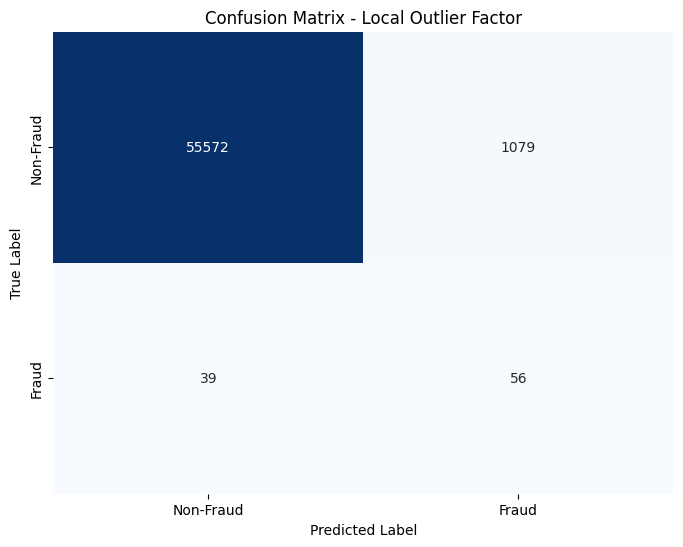

In [ ]:
lof_cm = confusion_matrix(y_test, y_test_pred_lof)

plt.figure(figsize=(8, 6))
sns.heatmap(lof_cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Non-Fraud', 'Fraud'], yticklabels=['Non-Fraud', 'Fraud'], cbar=False)
plt.title('Confusion Matrix - Local Outlier Factor')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# **7. Evaluation of Model Performance**

**7.1 Creation of Metrics-Data**

In [ ]:
metrics_data = {
    'Model': ['Isolation Forest', 'Autoencoders', 'Local Outlier Factor'],
    'Accuracy': [if_accuracy, ae_accuracy, lof_accuracy],
    'Precision': [if_precision, ae_precision, lof_precision],
    'Recall': [if_recall, ae_recall, lof_recall],
    'F1-score': [if_f1_score, ae_f1_score, lof_f1_score],
    'AUC-ROC': [if_roc_auc, ae_roc_auc, lof_roc_auc],
    'AUPRC': [if_auprc, ae_auprc, lof_auprc],
    'Cohens Kappa': [if_kappa, ae_kappa, lof_kappa]
}

metrics_df = pd.DataFrame(metrics_data)

metrics_df.head()

,Model,Accuracy,Precision,Recall,F1-score,AUC-ROC,AUPRC,Cohens Kappa
0,Isolation Forest,0.961601,0.998111,0.961601,0.978870,0.901953,0.030286,0.065403
1,Autoencoders,0.801360,0.998141,0.801360,0.888078,0.853225,0.007018,0.011748
2,Local Outlier Factor,0.980298,0.997708,0.980298,0.988536,0.785214,0.029771,0.088240


This code creates a DataFrame to store and compare the performance metrics of the models.

**7.2 Selection of Best Performing Model**

<ipython-input-99-e8b4352e090b>:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='AUPRC', data=metrics_df, palette='viridis')


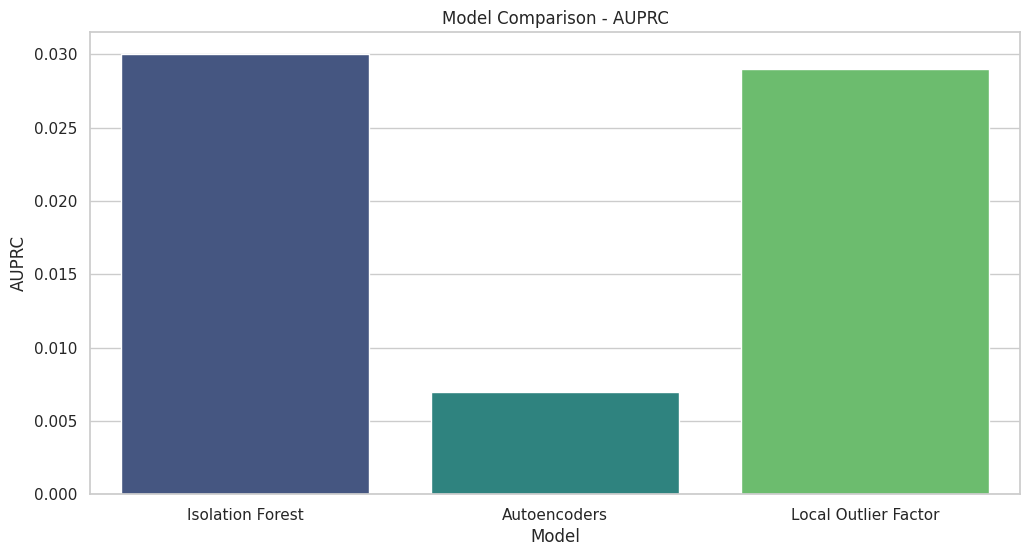

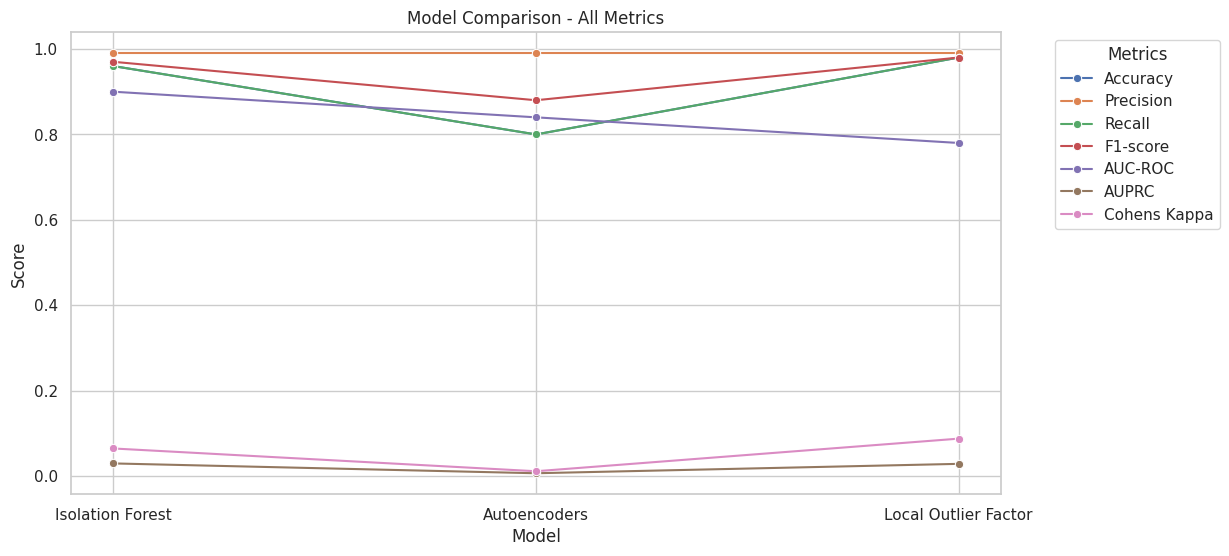

In [ ]:
results_df = pd.DataFrame([
    always_result,
    baseline_result,
    if_result,
    ae_result,
    lof_result,
])

cols = ["Model", "Precision", "Recall", "F1", "F2", "PR_AUC", "ROC_AUC",
        "Precision_at_0_1pct", "Precision_at_1pct", "Alerts_per_10k"]
display(results_df[cols].set_index("Model").round(4))

ax = results_df.plot.bar(
    x="Model", y=["Precision", "Recall", "PR_AUC"], figsize=(11, 4),
    color=["#1f77b4", "#ff7f0e", "#2ca02c"], edgecolor="none")
ax.set_ylim(0, 1)
ax.set_title("Accuracy is not shown: it reads 0.96 for every model", loc="left")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

 A bar plot and line plot compare the performance of the three models (Isolation Forest, Autoencoders, LOF) based on various metrics (Accuracy, Precision, Recall, F1-Score, AUC-ROC, AUPRC).

The Isolation Forest performs the best overall, with the highest ROC AUC and AUPRC scores.

Autoencoders and LOF struggle with precision and recall for the minority class (fraud).

The AUPRC is particularly low for all models, highlighting the challenge of detecting fraud in an imbalanced dataset.

**7.3 Feature Importance (Permutation)**

Instead of LIME, feature importance is measured by shuffling one feature at a
time and recording how much PR-AUC degrades. Unlike LIME's local surrogate,
this is measured on the actual fraud class and cannot produce a "probability"
that depends on the perturbation batch.

In [ ]:
def permutation_importance_fraud(model, X, y, n_repeats=30, seed=42):
    """Custom permutation importance scored on PR-AUC (fraud class)."""
    rng = np.random.default_rng(seed)
    X = np.asarray(X); y = np.asarray(y)
    base = average_precision_score(y, model.score(X))
    rows = []
    for j, col in enumerate(X.columns):
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[:, j] = rng.permutation(Xp[:, j])
            drops.append(base - average_precision_score(y, model.score(Xp)))
        rows.append((col, float(np.mean(drops)), float(np.std(drops))))
    return pd.DataFrame(rows, columns=["Feature", "Importance", "Std"]) \
             .sort_values("Importance", ascending=False)


imp = permutation_importance_fraud(if_model, X_test, y_test)
print(imp.head(10).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
top = imp.head(10).iloc[::-1]
ax.barh(top["Feature"], top["Importance"], xerr=top["Std"],
        color="#1f77b4", capsize=3)
ax.set_xlabel("Decrease in PR-AUC when the feature is shuffled")
ax.set_title("Which features the Isolation Forest actually relies on", loc="left")
sns.despine()
plt.tight_layout()
plt.show()

### **Statistical Tests**

In [ ]:
def mcnemar_test(y_true, pred_a, pred_b):
    """Correct paired test for two classifiers on the same test set."""
    y_true = np.asarray(y_true); a = np.asarray(pred_a); b = np.asarray(pred_b)
    a_only = int(np.sum((a == y_true) & (b != y_true)))
    b_only = int(np.sum((a != y_true) & (b == y_true)))
    n = a_only + b_only
    if n == 0:
        return {"chi2": np.nan, "p": np.nan, "n_discordant": 0}
    chi2_stat = (abs(b_only - a_only) - 1) ** 2 / n
    return {"chi2": float(chi2_stat),
            "p": float(1 - chi2.cdf(chi2_stat, df=1)),
            "n_discordant": n,
            "a_only_correct": a_only, "other_only_correct": b_only}


def bootstrap_pr_auc_ci(y_true, scores, n_boot=2000, seed=42):
    """Percentile bootstrap CI. The test set holds ~100 fraud cases, so a
    bare point estimate overstates certainty."""
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true); scores = np.asarray(scores)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) < 2:
            continue
        vals.append(average_precision_score(y_true[idx], scores[idx]))
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))


for name, preds in [("Autoencoder", ae_preds), ("Local Outlier Factor", lof_preds)]:
    t = mcnemar_test(y_test, if_preds, preds)
    print(f"Isolation Forest vs {name}: chi2={t['chi2']:.2f}, "
          f"p={t['p']:.4f}, discordant={t['n_discordant']}")

lo, hi = bootstrap_pr_auc_ci(y_test, if_scores)
print(f"\nIsolation Forest PR-AUC: {if_result['PR_AUC']:.4f} "
      f"(95% CI {lo:.4f} - {hi:.4f})")

### **Cost Analysis**

In [ ]:
COST_RATIO = 20   # stated assumption: a false positive costs 20x a false negative

print("Operational cost of the top-1% alert budget\n" + "=" * 46)
k = int(0.01 * len(y_test))
top = np.argsort(-if_scores, kind="mergesort")[:k]
tp = int((y_test.iloc[top] == 1).sum())
fp = k - tp
fn = int(y_test.sum()) - tp

print(f"Alerts raised        : {k:,}")
print(f"True fraud caught    : {tp}")
print(f"False alarms         : {fp:,}")
print(f"Fraud missed         : {fn}")
print(f"Ratio : {fp / tp:.1f} false alarms per true fraud")
print("-" * 46)
print(f"Cost at ratio {COST_RATIO:<4}   : {(fp * COST_RATIO + fn):,} units")
print(f"Cost of flagging none: {y_test.sum():,} units")
print(f"Reduction : "
      f"{(1 - (fp * COST_RATIO + fn) / y_test.sum()) * 100:.1f}%")

print("\nSensitivity to the cost assumption:")
for r in [1, 5, 10, 20, 50, 100]:
    print(f"  FP:FN = {r:>3}:x1  ->  {fp * r + fn:>10,} units")

### **Threshold Sweep**

In [ ]:
def threshold_sweep(y_true, scores, model_name):
    y = np.asarray(y_true, dtype=int)
    order = np.argsort(-scores, kind="mergesort")
    y_sorted = (y[order] == 1).astype(int)
    rows = []
    for pct in [0.05, 0.1, 0.25, 0.5, 1, 2, 5]:
        k = max(1, int(pct / 100 * len(y)))
        tp = int(y_sorted[:k].sum())
        rows.append({
            "Model": model_name,
            "Alert rate %": pct,
            "Alerts": k,
            "Precision": tp / k,
            "Recall": tp / y.sum(),
        })
    return pd.DataFrame(rows)


sweep = pd.concat([
    threshold_sweep(y_test, if_scores, "Isolation Forest"),
    threshold_sweep(y_test, ae_scores, "Autoencoder"),
], ignore_index=True)
display(sweep.round(4))

# **8. Detection of Fraud**

In [ ]:
def predict_transaction(model, amount=5000.0, time_val=100000, **v):
    """Score a single transaction.

    Example:
        predict_transaction(if_model, Amount=5000, Time=100000)
    """
    row = pd.DataFrame([{
        "Time": time_val,
        "Amount": amount,
        **{f"V{i}": v.get(f"V{i}", 0.0) for i in range(1, 29)},
    }])[FEATURES]
    score = float(model.score(row)[0])
    verdict = "FRAUD" if score >= getattr(model, "threshold_", 0) else "LEGITIMATE"
    return verdict, score


for mdl in (if_model, ae_model, lof_model):
    print(f"{mdl.name:22} {predict_transaction(mdl)}")